### Code to extract documents for all chosen source domains in preparation for metaphor analysis

Chosen source domains:
- Cognitive Agency:
    - trainee -> Auszubildender
    - god -> Gott
- Behavioral Agency:
    - conversational partner: child, friend -> Kind, Freund
- Labor:
    - artist -> Künstler
    - assistant -> Assistent
    - doctor -> Arzt
    - (expert -> Experte)
    - teacher -> Lehrer
    - thief -> Dieb
    - programmer -> Programmierer
    - writer -> Author
    - (co)worker -> Kollege (Mitarbeiter)

In [6]:
from pprint import pprint
import os
import ast
import pandas as pd
import numpy as np
import string
import tqdm
from nltk import FreqDist
import matplotlib.pyplot as plt
import seaborn as sns

import gensim
from gensim.models import LdaModel
from sklearn.feature_extraction.text import TfidfVectorizer

import spacy
nlp = spacy.load('de_core_news_lg')

def flatten(xss):
    return [x for xs in xss for x in xs]

plots_dir = "plots/"

In [33]:
# preprocessing auxiliary functions

stopwords = open("config_files/spacy_stopwords.txt").read().replace("{", '[').replace("}",']')
stopwords = ast.literal_eval(stopwords)

# this one is not needed if working on Sentence_spacy
def remove_punctuation(corpus):
    cleaned_corpus = corpus.translate(str.maketrans('', '', string.punctuation))
    return(cleaned_corpus)

# remove stop words from text
def remove_stop_words_from_text(cleaned_corpus):
    out = [word for word in cleaned_corpus if not word in stopwords]
    out_text = ' '.join(out)
    return out_text  # , out

# search with stemm/lemma
def get_lemma(sent):
    doc = nlp(sent)
    return [token.lemma_ for token in doc]

In [34]:
# use tf-idf to get keywords from texts
# corpus a list of sentences/documents
# stopwords_l a list of stopwords in the target language if not english
def calc_tf_idf(corpus, stopwords_l= None):
    corpus_cleaned = [remove_punctuation(doc.lower()) for doc in corpus]
    if stopwords_l:
        corpus_cleaned = [remove_stop_words_from_text(doc.split()) for doc in corpus_cleaned]
        vectorizer = TfidfVectorizer(stop_words=stopwords_l, lowercase=True, ngram_range=(1,1))
    else:
        vectorizer = TfidfVectorizer(stop_words='english', lowercase=True, ngram_range=(1,1))
    # fit tfidf
    tfidf_m = vectorizer.fit_transform(corpus_cleaned) #transform
    #print(tfidf_m.shape)
    feature_array = vectorizer.get_feature_names_out()
    # top (20?) for every doc
    tfidf_sorting = np.argsort(tfidf_m.toarray()).flatten()[::-1] 
    top_n = feature_array[tfidf_sorting].tolist()[:30]
    #print(top_n)
    return top_n #array of list(s?)

In [35]:
# list of domains
source_doms = ['Auszubildender', 'Gott', 'Kind', 'Freund', 'Künstler', 'Assistent', 'Arzt', 'Lehrer', 'Dieb', 'Programmierer', 'Autor', 'Kollege']
source_doms_lemma = [get_lemma(x)[0].lower() for x in source_doms]
print(len(source_doms_lemma))
print(source_doms_lemma)

12
['auszubildende', 'gott', 'kind', 'freund', 'künstler', 'assistent', 'arzt', 'lehrer', 'dieb', 'programmierer', 'autor', 'kollege']


#### RegEx search for sentences 

In [38]:
# build lexcons for each domain, label some examples per domain using regex search
# get sents in Leipzig data, sort into doms

def get_sentences_doms(leipzig_main,source_doms_lemma, stopwords):
    sentences = {}
    sentences_doms = pd.DataFrame(columns=['id', 'sentence', 'lematrized', 'domain'])
    sentences_doms_re = pd.DataFrame(columns=['id', 'sentence', 'lematrized', 'domain'])

    d_counter = [0] * len(source_doms_lemma)
    d_counter_re = [0] * len(source_doms_lemma)
    for p in os.listdir(leipzig_main):
        print(p)
        if (x < 1000 for x in d_counter) and (x < 1000 for x in d_counter_re):
            sentences_file = os.path.join(leipzig_main, p, f"{p}-sentences.txt")
            # extract sentences
            sentences = open(sentences_file).readlines()
            n=1
            for chunk in tqdm.tqdm([sentences[i:i+n] for i in range(0, len(sentences), n)]):
                sent = chunk[0].split('\t')[1]
                sent_lemmas = get_lemma(sent)
                sent_lemmas = [x.lower() for x in sent_lemmas if not x.isdigit() and not x == '--' and not x == '\n']
                try:
                    topn = calc_tf_idf(chunk, stopwords_l=stopwords)
                except:
                    print("error in tfidf")
                    topn = []
                for d in source_doms_lemma:
                    if d in topn and d_counter[source_doms_lemma.index(d)] < 1000:
                        sentences_doms.loc[len(sentences_doms)] = [len(sentences_doms), sent.replace('"', ''), sent_lemmas, d]
                        d_counter[source_doms_lemma.index(d)] += 1                
                    if d in sent_lemmas and d_counter_re[source_doms_lemma.index(d)] < 1000:
                        sentences_doms_re.loc[len(sentences_doms_re)] = [len(sentences_doms_re), sent.replace('"', ''), sent_lemmas, d]
                        d_counter_re[source_doms_lemma.index(d)] += 1
            sentences_doms.to_csv('generated_data/domains.csv', sep='\t')
            sentences_doms_re.to_csv('generated_data/domains_re.csv', sep='\t')
            print(d_counter,d_counter_re)
        else:
            print(d_counter,d_counter_re)
            break
    return sentences_doms, sentences_doms_re

In [ ]:
leipzig_main = "deu_news"
doms = get_sentences_doms(leipzig_main, source_doms_lemma, stopwords)

deu_news_2003_1M


100%|██████████| 1000000/1000000 [1:29:52<00:00, 185.44it/s]


[80, 813, 1000, 1000, 1000, 91, 818, 1000, 41, 35, 961, 516] [51, 1000, 1000, 1000, 1000, 153, 1000, 1000, 128, 42, 1000, 1000]
deu_news_2013_1M


100%|██████████| 1000000/1000000 [1:28:29<00:00, 188.33it/s]


[151, 1000, 1000, 1000, 1000, 181, 1000, 1000, 135, 88, 1000, 828] [86, 1000, 1000, 1000, 1000, 328, 1000, 1000, 420, 115, 1000, 1000]
deu_news_2007_1M


100%|██████████| 1000000/1000000 [1:30:17<00:00, 184.59it/s]


... (34 outputs left out)

[1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] [897, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
deu_news_2001_1M


100%|██████████| 1000000/1000000 [1:32:12<00:00, 180.76it/s]


[1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] [938, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
deu_news_2011_1M


 75%|███████▍  | 746048/1000000 [1:06:46<33:49, 125.11it/s] 

In [ ]:
combined = pd.concat([doms[0], doms[1]]).drop_duplicates(subset=['sentence']).reset_index(drop=True)
combined['id'] = combined.index
combined.to_csv('generated_data/domains.csv')

                                            sentence  \
0     Der andere unverdiente Freund wohnt nebenan.\n   
1  Paul Rivlin, Autor von Economic Policy and Per...   
2  Er hat die Maus nicht fangen können, Gott sei ...   
3  Der 32-jährige Pedro Halffter ist sicherlich e...   
4  Auch wenn sie noch per Nasensonde ernährt wird...   

                                          lemmatized    domain  
0  ['der', 'anderer', 'unverdient', 'freund', 'wo...    freund  
1  ['paul', 'rivlin', 'autor', 'von', 'economic',...     autor  
2  ['er', 'haben', 'der', 'maus', 'nicht', 'fange...      gott  
3  ['der', '32-jährig', 'pedro', 'halffter', 'sei...  künstler  
4  ['auch', 'wenn', 'sie', 'noch', 'per', 'nasens...      kind  


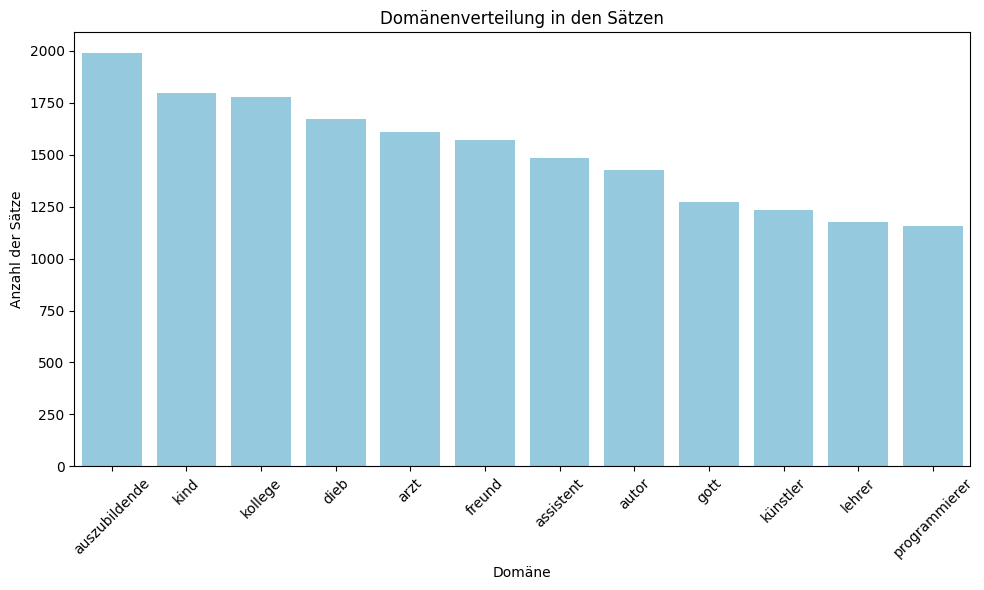

In [20]:
domains = pd.read_csv('generated_data/domains_all.csv', sep=',')
domains = domains.drop(columns=['Unnamed: 0','id'])
domains = domains.rename(columns={'lematrized': 'lemmatized'})
domains.to_csv('generated_data/domains_all.csv', sep=',', index=False)
print(domains.head())


#plot distribution of sentences per domain
plt.figure(figsize=(10,6))
sns.countplot(data=domains, x='domain', order=domains['domain'].value_counts().index,color='skyblue')
plt.xticks(rotation=45)
plt.title('Domänenverteilung in den Sätzen')
plt.xlabel('Domäne')
plt.ylabel('Anzahl der Sätze')
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, 'domain_distribution.png'))
plt.show()


#### Cluster sentences for each domain

In [ ]:
# set values and create list of processed words here souce_doms and source_doms_lemma

# create bag of words for lda model
dictionary = gensim.corpora.Dictionary([s.split() for s in source_doms_lemma])
corpus = [dictionary.doc2bow(value) for value in [s.split() for s in source_doms_lemma]]

# train the lda model
lda_model = gensim.models.ldamodel.LdaModel(
    corpus=corpus, 
    num_topics=len(source_doms_lemma), 
    id2word=dictionary, 
    passes=100,
    eval_every = 1)
lda_model.save('lda_train.model')
lda_topics = lda_model.print_topics()

# print the topics to screen
for t in lda_topics:
    print(f"Topic {t[0]+1}: {t[1]}")

Topic 1: 0.542*"author" + 0.042*"lehrer" + 0.042*"assistent" + 0.042*"programmierer" + 0.042*"dieb" + 0.042*"auszubildende" + 0.042*"arzt" + 0.042*"kind" + 0.042*"freund" + 0.042*"gott"
Topic 2: 0.542*"kollege" + 0.042*"lehrer" + 0.042*"author" + 0.042*"programmierer" + 0.042*"dieb" + 0.042*"auszubildende" + 0.042*"arzt" + 0.042*"kind" + 0.042*"freund" + 0.042*"gott"
Topic 3: 0.542*"künstler" + 0.042*"lehrer" + 0.042*"assistent" + 0.042*"author" + 0.042*"programmierer" + 0.042*"dieb" + 0.042*"auszubildende" + 0.042*"kind" + 0.042*"freund" + 0.042*"arzt"
Topic 4: 0.361*"freund" + 0.361*"gott" + 0.028*"dieb" + 0.028*"assistent" + 0.028*"author" + 0.028*"programmierer" + 0.028*"auszubildende" + 0.028*"lehrer" + 0.028*"künstler" + 0.028*"arzt"
Topic 5: 0.083*"lehrer" + 0.083*"assistent" + 0.083*"author" + 0.083*"programmierer" + 0.083*"dieb" + 0.083*"auszubildende" + 0.083*"arzt" + 0.083*"kind" + 0.083*"freund" + 0.083*"gott"
Topic 6: 0.542*"auszubildende" + 0.042*"lehrer" + 0.042*"author"

Score: 0.0833333358168602	 Topic: 0.542*"author"
Score: 0.0833333358168602	 Topic: 0.542*"kollege"
Score: 0.0833333358168602	 Topic: 0.542*"künstler"
Score: 0.0833333358168602	 Topic: 0.361*"freund"
Score: 0.0833333358168602	 Topic: 0.083*"auszubildende"
Score: 0.0833333358168602	 Topic: 0.542*"auszubildende"
Score: 0.0833333358168602	 Topic: 0.542*"assistent"
Score: 0.0833333358168602	 Topic: 0.361*"kind"
Score: 0.0833333358168602	 Topic: 0.542*"lehrer"
Score: 0.0833333358168602	 Topic: 0.542*"dieb"
Score: 0.0833333358168602	 Topic: 0.083*"auszubildende"
Score: 0.0833333358168602	 Topic: 0.542*"programmierer"
Auszubildender: 1
Gott: 1
Kind: 1
Freund: 1
Künstler: 1
Assistent: 1
Arzt: 1
Lehrer: 1
Dieb: 1
Programmierer: 1


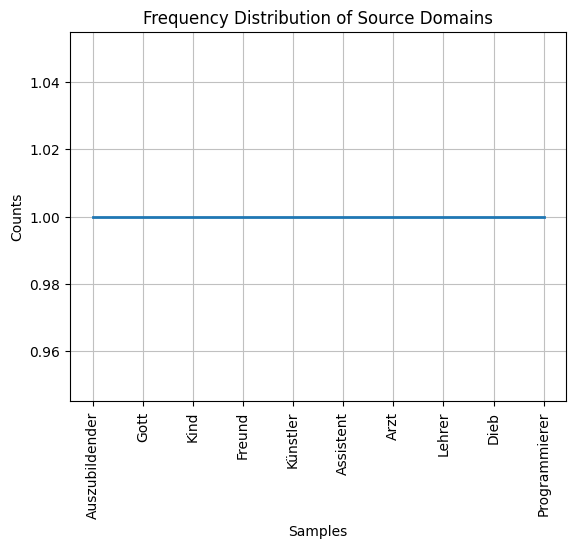

<Axes: title={'center': 'Frequency Distribution of Source Domains'}, xlabel='Samples', ylabel='Counts'>

In [ ]:
# classify domains based on the ten LDA topics 

# create bag of words from moral values list and classify topics according to values list
bow_vector = dictionary.doc2bow(source_doms)
for index, score in sorted(lda_model[bow_vector], key=lambda tup: -1*tup[1]):
    print("Score: {}\t Topic: {}".format(score, lda_model.print_topic(index, 1)))

# create frequency distribution graph from the moral values table
# create freq dist list and graph from moral values list
dist = FreqDist(source_doms)
dist_values = dist.most_common(10)
for v in dist_values:
    print(f"{v[0]}: {v[1]}")

dist.plot(10, title="Frequency Distribution of Source Domains")


In [ ]:
'''
# use to cluster, save files
source_d_path = "source_domains"
dom_sentences = pd.DataFrame(columns=['id','domain','sentence'])
for p in source_doms_lemma:
    cluster_results = {}
    for domain_lemma in sentences_all['sentence']:
        if p in domain_lemma:
            cluster_results[sentences_all.loc[sentences_all['sentence'] == domain_lemma, 'id'].values[0]] = domain_lemma

    # to df
    s_id = 0
    sentence = ''
    dom_sentences.loc[len(dom_sentences)] = [s_id, p, sentence]
    # save to file
    dom_sentences.to_csv(os.path.join(source_d_path, p, f"{p}_sentences.txt"))
'''

'\n# use to cluster, save files\nsource_d_path = "source_domains"\ndom_sentences = pd.DataFrame(columns=[\'id\',\'domain\',\'sentence\'])\nfor p in source_doms_lemma:\n    cluster_results = {}\n    for domain_lemma in sentences_all[\'sentence\']:\n        if p in domain_lemma:\n            cluster_results[sentences_all.loc[sentences_all[\'sentence\'] == domain_lemma, \'id\'].values[0]] = domain_lemma\n\n    # to df\n    s_id = 0\n    sentence = \'\'\n    dom_sentences.loc[len(dom_sentences)] = [s_id, p, sentence]\n    # save to file\n    dom_sentences.to_csv(os.path.join(source_d_path, p, f"{p}_sentences.txt"))\n'